In [3]:
import os
import hydra
from omegaconf import OmegaConf, DictConfig

import torch
import lightning as L
from lightning.pytorch.loggers import WandbLogger
from lightning.pytorch.callbacks import ModelCheckpoint

from rl4co.utils.trainer import RL4COTrainer
from rl4co.envs import get_env

from models.zoo.icam.model import ICAM
from rl4co.utils.ops import batchify, unbatchify, gather_by_index

cfg = OmegaConf.load('./configs/icam.yaml')

L.seed_everything(cfg.get("seed", 1234))

env_params = cfg.env
model_params_dict = OmegaConf.to_container(cfg.model, resolve=True)
if env_params.env_name == "shpp":
    from envs.routing.shpp.env import SHPPEnv
    from models.nn.env_embeddings.init import SHPPInitEmbedding
    from models.nn.env_embeddings.context import SHPPContext
    from rl4co.models.nn.env_embeddings.dynamic import StaticEmbedding
    del env_params.env_name
    env = SHPPEnv(**env_params)
    
    model_params_dict['policy_kwargs'].update({
        "init_embedding": SHPPInitEmbedding(embed_dim=cfg.embed_dim),
        "context_embedding": SHPPContext(embed_dim=cfg.embed_dim),
        "dynamic_embedding": StaticEmbedding(),
    })
else:
    env = get_env(**env_params)

if model_params_dict['policy_kwargs']['pointer'] == "poly":
    from rl4co.models.nn.attention import PolyNetAttention
    model_params_dict['policy_kwargs']['pointer'] = PolyNetAttention(
        **cfg.poly, 
        poly_layer_dim=cfg.embed_dim*2
    )

if model_params_dict['policy_kwargs']['encoder'] == "am":
    from rl4co.models.zoo.am.encoder import AttentionModelEncoder
    model_params_dict['policy_kwargs']['encoder'] = AttentionModelEncoder(
        embed_dim=cfg.embed_dim,
        num_heads=cfg.num_heads,
        num_layers=model_params_dict['policy_kwargs']['num_encoder_layers'],
        normalization=model_params_dict['policy_kwargs']['normalization'],
    )

model = ICAM(
    env=env,
    **model_params_dict,
)
if cfg.ckpt_path:
    ckpt_state_dict = torch.load(cfg.ckpt_path)['state_dict']
    model.load_state_dict(ckpt_state_dict)

Seed set to 1234


Problem 1 | Cost: 9.685
Problem 2 | Cost: 9.571
Problem 3 | Cost: 10.336


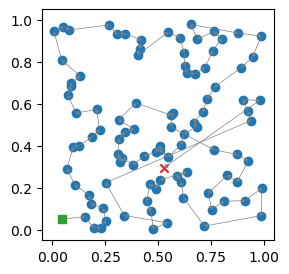

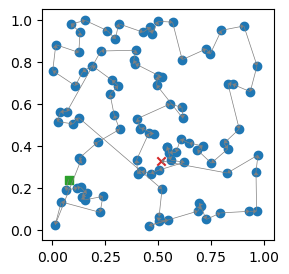

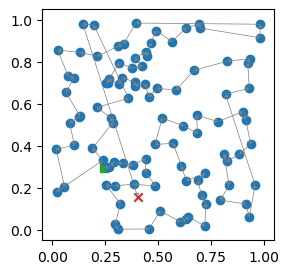

In [4]:
device = "cpu"
n_samples = 3
num_starts = cfg.model.num_starts
td_init = env.reset(batch_size=[n_samples]).to(device)
model = model.to(device)

out = model(td_init.clone(), 
            phase="test", 
            decode_type="greedy",
            multisample=True, 
            num_starts=num_starts, 
            return_actions=True
            )
actions = out['actions'].cpu().detach()
rewards = out['reward'].cpu().detach()
if num_starts > 1:
    actions = unbatchify(actions, num_starts)
    rewards = unbatchify(rewards, num_starts)
    max_rewards, max_idxs = rewards.max(dim=1)
    best_actions = gather_by_index(actions, max_idxs, dim=1)
else:
    max_rewards = rewards
    best_actions = actions

for i in range(3):
    print(f"Problem {i+1} | Cost: {-max_rewards[i]:.3f}")
    env.render(td_init[i], best_actions[i])

In [18]:
improved_actions = env.local_search(td_init, actions)
improved_rewards = env.get_reward(td_init, improved_actions)

for i in range(3):
    print(f"Problem {i+1} | Improved Cost: {-improved_rewards[i]:.3f}")
    env.render(td_init[i], improved_actions[i])

NotImplementedError: Local is not implemented yet for shpp environment